# Shape the data

In this tutorial we measure one tumor with each assay of `iscc`, in the order bulk DNA, single-cell DNA, scRNA-seq and Visium, and change the data each assay produces.
For each assay we choose a technology preset, switch the measurement biases on and off, and fit the assay parameters to a real data set.
We then simulate batches and write the data in the formats that analysis tools read.
[Shape the tumor](02_shape_the_tumor.ipynb) changes the tumor itself.

In [1]:
%matplotlib inline
import os, shutil, tempfile, urllib.request, warnings
os.environ["KMP_WARNINGS"] = "0"  # silence a deprecation notice of OpenMP in the Scrublet dependencies
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="nopython is set")
warnings.filterwarnings("ignore", message="Variable names are not unique")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import squidpy as sq
from scipy.spatial import cKDTree
from sklearn.metrics import roc_auc_score, silhouette_score

import iscc.pregrown
from iscc.sample import Resection
from iscc.data import (bulkDNA, scDNA, scRNA, Visium, estimate_dna, estimate_rna, estimate_visium,
                       morans_i, run_scrna_batches, concat_batches)
from iscc.integrations import to_anndata, biological_types

sc.settings.verbosity = 0

## One tumor, sampled twice

`iscc.pregrown.immune()` loads the tumor of the paper's regime with immune cells, grown once to about 200,000 cancer cells in a 1 cm field of eight glands on the arm-level human genome, with T and NK cells in the stroma that kill nearby cancer cells unless the immune resistance of the cancer cells protects them ([pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors)).
We cut the resected specimen in two, dissociate the tumor of one half for the sequencing assays (its cancer demes and a rim of one deme, [`Resection.cancer_region`](https://pedrofale.github.io/iscc/reference/Resection/), the piece a pathologist sends for dissociation) and put a thin section of the other half on a Visium slide.

In [2]:
tumor = iscc.pregrown.immune()

specimen = Resection(tumor)
half_seq, half_section = specimen.bisect(frac=0.5, axis="y")
piece = sorted(set(specimen.cancer_region(margin=1)) & set(half_seq))
cells = specimen.dissociate(piece, max_cells=6000, layers=["scdna", "scrna"], seed=0)
section = specimen.slice(half_section, depth_frac=0.5, max_cells=160_000, layers="visium")

cell_type = pd.Series(biological_types(cells["cell_type"]["cell_id"]), index=cells["cell_type"].index)
print(f"tumor: {tumor.get_cancer_size():,} cancer cells of {tumor.get_tumor_size():,}")
print(f"dissociated tumor of one half: {len(cell_type):,} cells,", cell_type.value_counts().to_dict())
print(f"section: {len(section['cell_exp']):,} cells,",
      pd.Series(biological_types(section["cell_type"]["cell_id"])).value_counts().to_dict())

tumor: 200,064 cancer cells of 586,410
dissociated tumor of one half: 6,099 cells, {'cancer': 3884, 'stromal': 1904, 'immune': 201, 'epithelial': 110}
section: 124,125 cells, {'stromal': 63998, 'immune': 39323, 'cancer': 18474, 'epithelial': 2330}


The dissociation keeps a subsample of about 6,000 cells of its half, of which 64% are cancer cells.
The piece holds few immune cells, since the ducts hold none and a cancer birth in a full deme of the stroma pushes one out.
The section keeps half of the depth of each deme (`depth_frac=0.5`), which leaves 124,125 cells, a third of them immune cells.

## Bulk DNA

[`bulkDNA`](https://pedrofale.github.io/iscc/reference/bulkDNA/) pools the dissociated cells into one library.
The coverage of a locus is proportional to its pooled copy number and to a capture efficiency.
A Dirichlet-multinomial spreads the reads over the loci, and its concentration `kappa` sets how even the coverage is.
The default `kappa` is the value that [`estimate_dna`](https://pedrofale.github.io/iscc/reference/estimate_dna/) fitted to 20,000 sites of the GIAB HG002 benchmark genome (Zook et al., 2019).
It is stored with the number of loci it was fitted on (`kappa_loci`), and the assay rescales it to its own loci.
The breadth (`"wgs"`, `"wes"` or `"panel"`) sets which loci are read, the mean depth and the dominant capture bias.
To compare runs we divide the coverage of each locus by its true pooled copy number and report the coefficient of variation (CV) of this coverage per copy over loci.
We also report the standard deviation of the variant allele fraction (VAF) about its true value at the germline heterozygous loci, which the pregrown tumor carries at the density of a genotyping array.

In [3]:
het_loci = cells["cell_snv"].columns[tumor.germline_sites[tumor.germline_zygosity == "het"]]

def bulk_summary(run):
    od = run.observed_data
    per_copy = od["coverage"] / od["true_cn"]
    return {"loci": len(od), "mean coverage": od["coverage"].mean(),
            "coverage CV": per_copy.std() / per_copy.mean(),
            "VAF error sd at germline hets": (od["vaf"] - od["true_alt_fraction"])[od.index.isin(het_loci)].std()}

bulk = {"WGS 30x": bulkDNA(breadth="wgs", seed=1).run(cells),
        "WGS 100x": bulkDNA(breadth="wgs", mu_depth=100, seed=1).run(cells),
        "WES": bulkDNA(breadth="wes", seed=1).run(cells),
        "panel": bulkDNA(breadth="panel", seed=1).run(cells)}
print(f"tumor purity of the pool: {bulk['WGS 30x'].purity:.2f}, "
      f"{len(het_loci):,} germline heterozygous loci")
pd.DataFrame({b: bulk_summary(r) for b, r in bulk.items()}).T.round(2)

tumor purity of the pool: 0.64, 1,714 germline heterozygous loci


,loci,mean coverage,coverage CV,VAF error sd at germline hets
WGS 30x,6001.0,30.0,0.48,0.11
WGS 100x,6001.0,100.0,0.44,0.06
WES,1800.0,120.0,0.55,0.05
panel,30.0,1500.0,0.56,0.01


Cancer cells make up 64% of the pool, and this purity is what a copy number or clone caller has to estimate.
At the default concentration the CV of the WGS coverage per copy is 0.48 at 30x and 0.44 at 100x, close to the 0.41 of HG002 at its depth of 479x.
At the germline heterozygous loci this standard deviation is 0.11 at 30x and 0.06 at 100x.
WES reads 30% of the loci at 120x and the panel reads 30 loci at 1,500x.
Both add a per-target capture efficiency (`capture_sigma` 0.3 and 0.45), which raises their CV to 0.55 and 0.56.
We plot the coverage per copy along the genome at the default concentration and at a tenfold lower one, and its median against GC content for three strengths of the GC bias (`gc_curve_sigma`).

coverage CV with a tenfold lower kappa: 1.35


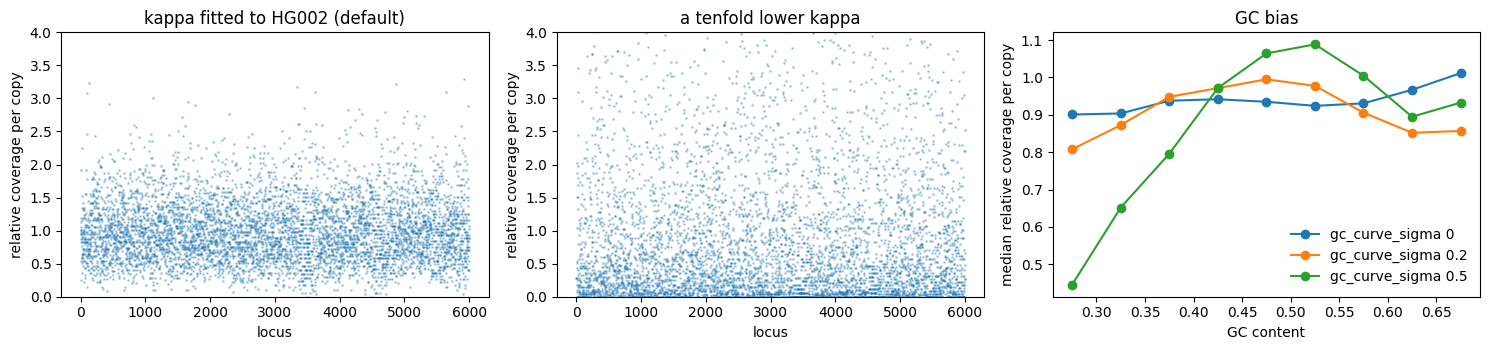

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
lumpy = bulkDNA(breadth="wgs", kappa=12_124, kappa_loci=20_000, seed=1).run(cells)
print(f"coverage CV with a tenfold lower kappa: {bulk_summary(lumpy)['coverage CV']:.2f}")
for ax, run, title in [(axes[0], bulk["WGS 30x"], "kappa fitted to HG002 (default)"),
                       (axes[1], lumpy, "a tenfold lower kappa")]:
    per_copy = run.observed_data["coverage"] / run.observed_data["true_cn"]
    ax.scatter(np.arange(len(per_copy)), per_copy / per_copy.mean(), s=1, alpha=0.3)
    ax.set(title=title, xlabel="locus", ylabel="relative coverage per copy", ylim=(0, 4))
gc_bins = np.arange(0.2, 0.81, 0.05)
for gc_sigma in [0.0, 0.2, 0.5]:
    od = bulkDNA(breadth="wgs", gc_curve_sigma=gc_sigma, seed=1).run(cells).observed_data
    per_copy = od["coverage"] / od["true_cn"]
    curve = (per_copy / per_copy.mean()).groupby(pd.cut(od["gc"], gc_bins), observed=True).agg(["median", "size"])
    curve = curve[curve["size"] >= 50]                       # bins with enough loci
    axes[2].plot([b.mid for b in curve.index], curve["median"], "o-", label=f"gc_curve_sigma {gc_sigma:g}")
axes[2].set(title="GC bias", xlabel="GC content", ylabel="median relative coverage per copy")
axes[2].legend(frameon=False)
plt.tight_layout()

A tenfold lower `kappa` raises the CV to 1.35, leaving most loci with few reads and a few with several times the mean.
The GC bias lowers the coverage of GC-rich and GC-poor loci, and at the strongest setting most of all that of GC-poor loci.

## Single-cell DNA

[`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) draws the coverage of each cell separately, so that each cell has a different amplification profile.
It loses one allele of a heterozygous locus with probability `ado_rate` (allelic dropout) and overdisperses the allele counts by `beta_binom_conc`.
It also merges a fraction `doublet_rate` of the cells with a partner and marks them in `obs["is_doublet"]`.
We measure the same 300 cells with four settings.
The default keeps the depth of the breadth (9 reads per locus at WGS) with the coverage dispersion of DLP+.
The presets `platform="dlp"` and `platform="tapestri"` take the values that [`estimate_dna`](https://pedrofale.github.io/iscc/reference/estimate_dna/) fitted to 40 cells of the DLP+ data set OV2295 (Laks et al., 2019) and to 800 cells of a 584-amplicon Tapestri panel (Mays et al., 2024).
DLP+ counts the reads of a 500 kb bin at each locus, and its data carry no allele counts, so its allele layer keeps the single-cell defaults.
The Tapestri preset reads 30 loci unless told otherwise, and we give it a tenth of the loci (`target_genes=0.1`), about as many as the amplicons of the panel it was fitted on.
The MDA-like setting is our choice rather than a fit, with the DLP+ preset, a tenfold lower `kappa` for the lumpier coverage of multiple displacement amplification, and a dropout of 0.3.

In [5]:
platforms = {
    "default": dict(),
    "DLP+": dict(platform="dlp"),
    "MDA-like": dict(platform="dlp", kappa=20_280, kappa_loci=5787, ado_rate=0.3),
    "Tapestri": dict(platform="tapestri", target_genes=0.1),
}
assayed = np.random.default_rng(0).choice(cell_type.index, size=300, replace=False)
sc_dna = {p: scDNA(seed=2, **kw).run(cells, cell_subset=assayed) for p, kw in platforms.items()}

def balanced_hets(run):
    # cell-locus pairs that are heterozygous at two copies and have at least 10 reads
    return (run.true_alt_fraction.values == 0.5) & (run.true_cn.values == 2) & (run.coverage.values >= 10)

def scdna_summary(run):
    cov, two = run.coverage.values.astype(float), run.true_cn.values == 2
    cv = [cov[i, two[i]].std() / cov[i, two[i]].mean() for i in range(len(cov))
          if two[i].sum() > 20 and cov[i, two[i]].sum() > 0]
    vaf = run.vaf.values[balanced_hets(run)]
    return {"loci": cov.shape[1], "mean coverage": cov.mean(), "loci without reads": (cov == 0).mean(),
            "coverage CV at 2 copies": np.median(cv),
            "hets read as homozygous": np.mean((vaf <= 0.05) | (vaf >= 0.95))}

print("assayed cells:", cell_type[assayed].value_counts().to_dict())
pd.DataFrame({p: scdna_summary(r) for p, r in sc_dna.items()}).T.round(3)

assayed cells: {'cancer': 188, 'stromal': 95, 'immune': 12, 'epithelial': 5}


,loci,mean coverage,loci without reads,coverage CV at 2 copies,hets read as homozygous
default,6001.0,9.0,0.003,0.556,0.205
DLP+,6001.0,830.1,0.000,0.296,0.197
MDA-like,6001.0,830.1,0.000,0.777,0.297
Tapestri,600.0,42.7,0.001,0.660,0.337


The default setting gives a CV of 0.56 at two copies, and 0.3% of the loci of a cell receive no read at 9 reads per locus.
The DLP+ preset gives a CV of 0.30, the MDA-like setting 0.78 and the Tapestri preset 0.66.
Most assayed cells are doubled cancer cells, in which a locus at two copies holds a smaller share of the reads than in a diploid cell, so its coverage varies more.
The share of heterozygous loci read as homozygous (0.20, 0.30 and 0.34) is close to each dropout rate (0.2, 0.3 and 0.325).
We plot the coverage of one cancer cell, scaled so that its median is the median true copy number of the cell, against its true copy number, and the VAF at the heterozygous loci of all assayed cells with and without dropout.

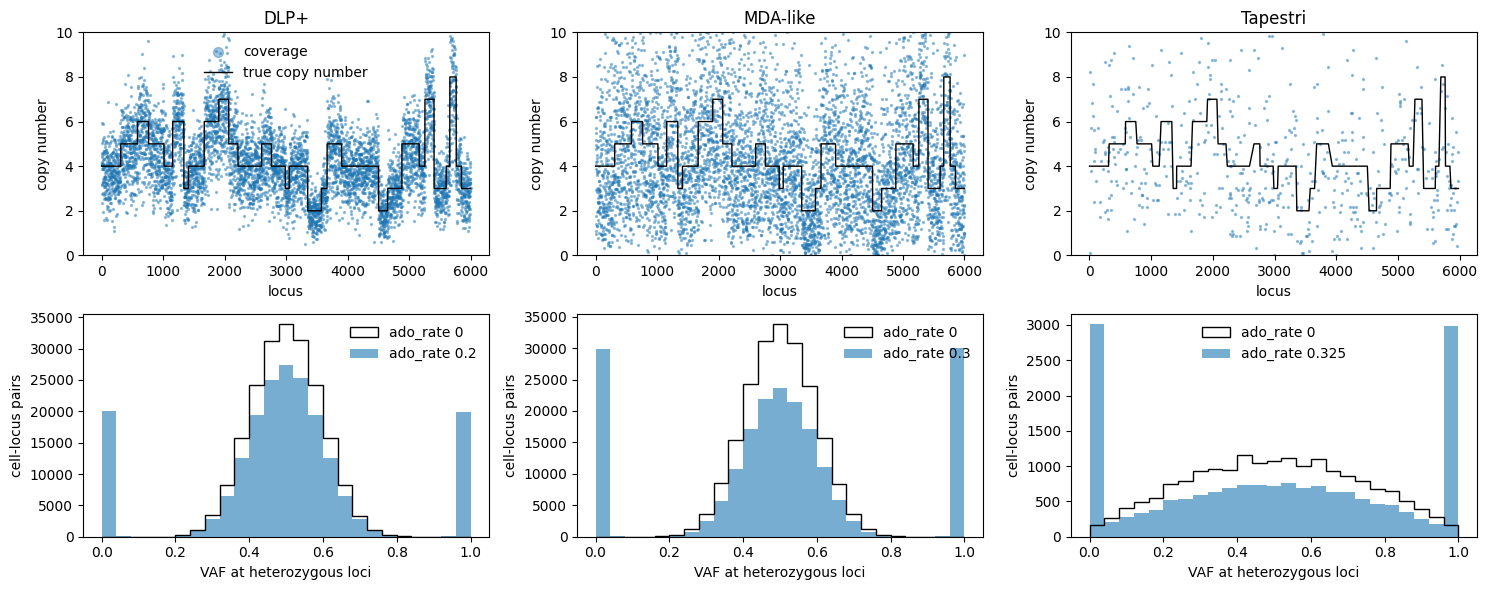

In [6]:
genome = cells["cell_snv"].columns
one_cell = next(c for c in assayed if cell_type[c] == "cancer")
bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for j, p in enumerate(["DLP+", "MDA-like", "Tapestri"]):
    run = sc_dna[p]
    pos = genome.get_indexer(run.genes)
    cov, true = run.coverage.loc[one_cell], run.true_cn.loc[one_cell]
    axes[0, j].scatter(pos, true.median() * cov / cov.median(), s=2, alpha=0.4, label="coverage")
    axes[0, j].plot(pos, true, color="k", lw=1, label="true copy number")
    axes[0, j].set(title=p, xlabel="locus", ylabel="copy number", ylim=(0, true.max() + 2))
    no_ado = scDNA(seed=2, **{**platforms[p], "ado_rate": 0.0}).run(cells, cell_subset=assayed)
    axes[1, j].hist(no_ado.vaf.values[balanced_hets(no_ado)], bins=bins, histtype="step", color="k",
                    label="ado_rate 0")
    axes[1, j].hist(run.vaf.values[balanced_hets(run)], bins=bins, alpha=0.6,
                    label=f"ado_rate {run.hypers.ado_rate:g}")
    axes[1, j].set(xlabel="VAF at heterozygous loci", ylabel="cell-locus pairs")
    axes[1, j].legend(frameon=False)
axes[0, 0].legend(frameon=False, markerscale=5)
plt.tight_layout()

The DLP+ coverage is close to the true copy number, the MDA-like coverage is too dispersed to separate neighboring copy number states, and the panel reads a tenth of the loci.
Dropout moves heterozygous loci from around 0.5 to 0 and 1, and the Tapestri allele counts spread far more around 0.5 because of their low `beta_binom_conc`.

On real data, `estimate_dna` takes the coverage and alternative-allele counts of each cell and locus, with the copy number called by a tool such as HMMcopy, and fits the parameters above.
We check it on the simulated Tapestri run, with the true copy number in place of a call and a mask of the heterozygous cell-locus pairs, which on real data come from germline SNPs.

In [7]:
tap = sc_dna["Tapestri"]
fit = estimate_dna(tap.coverage.values, tap.alt_counts.values, tap.true_cn.values,
                   modality="sc", breadth="panel", gc=tap.gc,
                   het_mask=(tap.true_alt_fraction.values > 0.15) & (tap.true_alt_fraction.values < 0.85))
print("fitted:", fit.fitted)
keys = ["mu_depth", "capture_sigma", "ado_rate", "beta_binom_conc"]
table = pd.DataFrame({"set": [tap.hypers.to_dict()[k] for k in keys],
                      "fitted": [fit.hypers.to_dict()[k] for k in keys]}, index=keys)
table.loc["kappa per locus"] = [tap.hypers.kappa / tap.hypers.kappa_loci, fit.hypers.kappa / fit.hypers.kappa_loci]
table.round(3)

fitted: ['mu_depth', 'gc_curve_sigma', 'kappa', 'capture_sigma', 'ado_rate', 'beta_binom_conc']


,set,fitted
mu_depth,42.700,42.700
capture_sigma,0.389,0.368
ado_rate,0.325,0.338
beta_binom_conc,4.510,4.287
kappa per locus,8.012,8.131


The fitted values are within 6% of the settings, and `fit.dna_kwargs()` passes them to `scDNA` or `bulkDNA`.

## scRNA-seq

[`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/) draws the UMI counts of each cell from the true expression of the cell, with a log-normal library size (`mu_lib`, `sigma_lib`) and a negative binomial (`dispersion`), and adds ambient RNA, doublets and an optional logistic dropout.
The `protocol` presets set all of them.
The 10x preset is a droplet protocol with ambient RNA and doublets, and the Smart-seq3 preset sorts one cell per well onto 384-well plates, deeper and with less ambient RNA.

In [8]:
def rna_summary(run):
    X = run.observed_counts.values
    return {"median UMIs": np.median(X.sum(1)), "median genes": np.median((X > 0).sum(1)),
            "zeros": (X == 0).mean(), "doublets": run.obs["is_doublet"].mean(),
            "plates": run.obs["plate"].nunique() if "plate" in run.obs else 0}

protocols = {p: scRNA(protocol=p, n_cells=2000, seed=1).run(cells) for p in ["10x", "smartseq3"]}
pd.DataFrame({p: rna_summary(r) for p, r in protocols.items()}).T.round(3)

,median UMIs,median genes,zeros,doublets,plates
10x,4168.5,1303.0,0.779,0.05,0.0
smartseq3,7807.0,1599.0,0.733,0.01,6.0


With the 10x preset the median is 4,169 UMIs per cell, close to the `mu_lib` of 4,000, and the median cell has about 1,300 detected genes.
Smart-seq3 is deeper (`mu_lib` 8,000, median 7,807 UMIs) and detects more genes per cell (1,599), and its 2,000 cells fill six plates of 384 wells.

### Dropout and depth

Neither preset drops counts beyond those of the negative binomial, because UMI counts carry no zeros beyond it (Svensson, 2020).
A logistic dropout can still be switched on with `dropout_mid`, the expected count at which a gene is dropped with probability one half.
We plot the fraction of cells with zero UMIs against the mean UMIs of each gene without and with dropout, and the genes detected per cell at three depths (`mu_lib`).

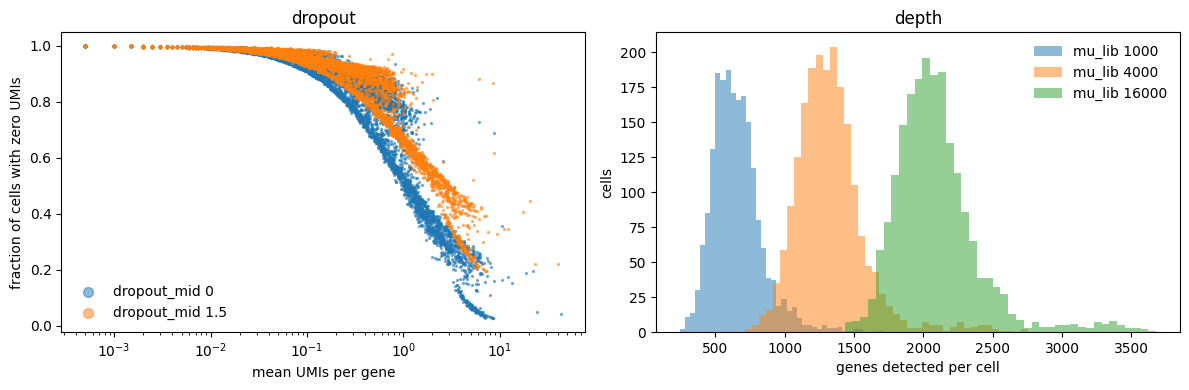

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mid in [0.0, 1.5]:
    X = scRNA(n_cells=2000, dropout_mid=mid, seed=1).run(cells).observed_counts.values
    axes[0].scatter(X.mean(0), (X == 0).mean(0), s=2, alpha=0.5, label=f"dropout_mid {mid:g}")
axes[0].set(xscale="log", xlabel="mean UMIs per gene", ylabel="fraction of cells with zero UMIs",
            title="dropout")
for depth in [1000, 4000, 16000]:
    X = scRNA(n_cells=2000, mu_lib=depth, seed=1).run(cells).observed_counts.values
    axes[1].hist((X > 0).sum(1), bins=40, alpha=0.5, label=f"mu_lib {depth}")
axes[1].set(xlabel="genes detected per cell", ylabel="cells", title="depth")
for ax in axes:
    ax.legend(frameon=False, markerscale=5)
plt.tight_layout()

Dropout raises the zero fraction of genes with more than about 0.1 UMIs per cell.
With the depth, the genes detected per cell rise from about 650 at 1,000 UMIs to about 2,100 at 16,000 UMIs.

### Dissociation

[`Resection.dissociate`](https://pedrofale.github.io/iscc/reference/Resection/) applies the biology of the dissociation itself.
Cells of each type are recovered with a probability set by `recovery_probs` (by default 0.09 for cancer and epithelial cells, 0.27 for the fibroblasts, endothelial cells and perivascular cells of the stroma, 0.45 for myeloid cells and 0.9 for T and NK cells and for B and plasma cells, as measured in breast tissue).
The expression of a random 5% of the genes of every recovered cell is then multiplied by `1 + stress_strength`.
`dissociate` materialises enough cells that about `max_cells` survive the recovery, as a single-cell run captures a target number of cells from a suspension. We dissociate the same piece again with both and measure the two dissociations with the same 10x run.

In [10]:
stressed = specimen.dissociate(piece, max_cells=6000, layers=["scdna", "scrna"],
                               recovery_probs="default", stress_strength=2.0, seed=0)
stress_genes = specimen.dissociation_meta["stress_genes"]
meta = specimen.dissociation_meta
print(f"recovered {meta['n_recovered']:,} of {meta['n_materialised']:,} materialised cells and kept "
      f"{len(stressed['cell_exp']):,}; {len(stress_genes)} stress genes")

rows = {}
for name, sample in [("plain dissociation", cells), ("recovery and stress", stressed)]:
    run = scRNA(n_cells=2000, seed=1).run(sample)
    counts = run.observed_counts
    rows[name] = pd.Series(biological_types(run.obs["clone"])).value_counts(normalize=True)
    rows[name]["stress-gene share of UMIs"] = (counts[stress_genes].sum(1) / counts.sum(1)).median()
pd.DataFrame(rows).T.round(3)

recovered 6,568 of 39,747 materialised cells and kept 6,000; 300 stress genes


,cancer,epithelial,immune,stress-gene share of UMIs,stromal
plain dissociation,0.628,0.021,0.036,0.056,0.316
recovery and stress,0.360,0.008,0.143,0.148,0.488


The recovery kept 6,568 of the 39,747 cells materialised, and the sample keeps 6,000 of them.
Among the measured cells, the share of cancer cells fell from 0.63 to 0.36, and the shares of stromal cells and immune cells rose from 0.32 to 0.49 and from 0.04 to 0.14, since cancer cells are the hardest to recover.
The 300 stress genes, multiplied by three, account for 14.8% of the UMIs of a cell instead of 5.6%.

### Ambient RNA and doublets

Ambient RNA (`ambient_frac`) replaces a share of the library of every cell by Poisson counts drawn from the pooled expression of its batch, so it adds no depth.
To see it, we take the 50 genes most specific to cancer cells in the true expression and measure their share of the UMIs of stromal cells.

In [11]:
expression = cells["cell_exp"]
cancer_markers = (expression[cell_type == "cancer"].mean()
                  / (expression[cell_type == "stromal"].mean() + 1e-6)).nlargest(50).index

rows = {}
for ambient in [0.0, 0.05, 0.2]:
    run = scRNA(n_cells=2000, ambient_frac=ambient, seed=1).run(cells)
    share = run.observed_counts[cancer_markers].sum(1) / run.observed_counts.sum(1)
    stromal = biological_types(run.obs["clone"]) == "stromal"
    rows[ambient] = {"median UMIs": run.obs["n_counts"].median(),
                     "cancer-marker share in stromal cells": share[stromal].mean()}
pd.DataFrame(rows).T.rename_axis("ambient_frac").round(4)

,median UMIs,cancer-marker share in stromal cells
ambient_frac,,
0.00,4197.0,0.0007
0.05,4168.5,0.0020
0.20,4181.0,0.0061


The share of cancer-marker UMIs in stromal cells rises from 0.07% without ambient RNA to 0.20% at the default `ambient_frac` of 0.05 and to 0.61% at 0.2, while the median library stays between 4,169 and 4,197 UMIs.

Doublets (`doublet_rate`) merge the counts of two barcodes.
We run Scrublet (`sc.pp.scrublet`), the doublet detector of scanpy, at two doublet rates.

In [12]:
rows = {}
for rate in [0.0, 0.15]:
    adata = scRNA(n_cells=2000, doublet_rate=rate, seed=1).run(cells).to_anndata()
    sc.pp.scrublet(adata, random_state=0)
    doublet = adata.obs["is_doublet"].values
    rows[rate] = {"doublets": doublet.mean(), "called by Scrublet": adata.obs["predicted_doublet"].mean()}
    if doublet.any():
        rows[rate]["UMIs, doublets / singlets"] = (adata.obs["n_counts"][doublet].median()
                                                    / adata.obs["n_counts"][~doublet].median())
        rows[rate]["Scrublet AUROC"] = roc_auc_score(doublet, adata.obs["doublet_score"])
pd.DataFrame(rows).T.rename_axis("doublet_rate").round(3)

,doublets,called by Scrublet,"UMIs, doublets / singlets",Scrublet AUROC
doublet_rate,,,,
0.00,0.00,0.000,NaN,NaN
0.15,0.15,0.001,2.09,0.871


Doublets have about twice the UMIs of single cells (2.09 times at the median).
Scrublet ranks them only in part (AUROC 0.87), and its automatic threshold flags 0.1% of the barcodes as doublets, against the 15% simulated.

### Fitting the assay to PBMC3k

[`estimate_rna`](https://pedrofale.github.io/iscc/reference/estimate_rna/) fits the library size and the dispersion of a real count matrix.
We fit it to PBMC3k, a data set of 2,700 blood cells from 10x Genomics, which `scanpy.datasets.pbmc3k()` downloads and which the paper also uses.
A simulated tumor draws the variation between its own cell types, so `estimate_rna` fits the dispersion within groups of similar cells (`cell_types="auto"`, found by k-means) rather than over all cells.
Counts alone cannot identify ambient RNA, doublets or a plate layout, so `est.carried` lists the values taken from the preset.
`estimate_rna` fits dropout only when asked (`fit_dropout=True`), and then only to the zeros beyond those of the negative binomial.

In [13]:
pbmc = sc.datasets.pbmc3k()
est = estimate_rna(pbmc, protocol="10x")
print(f"PBMC3k: {est.n_cells:,} cells, {est.n_genes:,} genes")
print(f"dispersion within {est.n_types} cell groups: {est.hypers.dispersion:.3f}, "
      f"over all cells pooled: {est.dispersion_pooled:.3f}")
print("fitted:", est.fitted)
print("carried from the 10x preset:", est.carried)
pd.Series(est.scrna_kwargs())

PBMC3k: 2,700 cells, 32,738 genes
dispersion within 8 cell groups: 0.345, over all cells pooled: 0.608
fitted: ['mu_lib', 'sigma_lib', 'dispersion']
carried from the 10x preset: ['ambient_frac', 'doublet_rate', 'kappa', 'well_sigma', 'n_wells', 'n_plates', 'plate_sigma', 'dropout_shape', 'sigma_batch', 'depth_batch_sigma']


protocol                    10x
sigma_batch                 0.1
mu_lib               2366.90037
sigma_lib              0.431431
dispersion             0.344871
ambient_frac               0.05
doublet_rate               0.05
dropout_mid                 0.0
dropout_shape               1.0
well_sigma                  0.0
n_wells                       0
n_plates                      0
plate_sigma                 0.0
depth_batch_sigma          0.05
dtype: object

mean depth drawn for this batch: 2,570 UMIs (fitted mu_lib 2,367)
PBMC3k: median 2,197 UMIs per cell, CV 0.46


simulated with the fit: median 2,406 UMIs per cell, CV 0.48


dropout midpoint fitted on request: 0.0


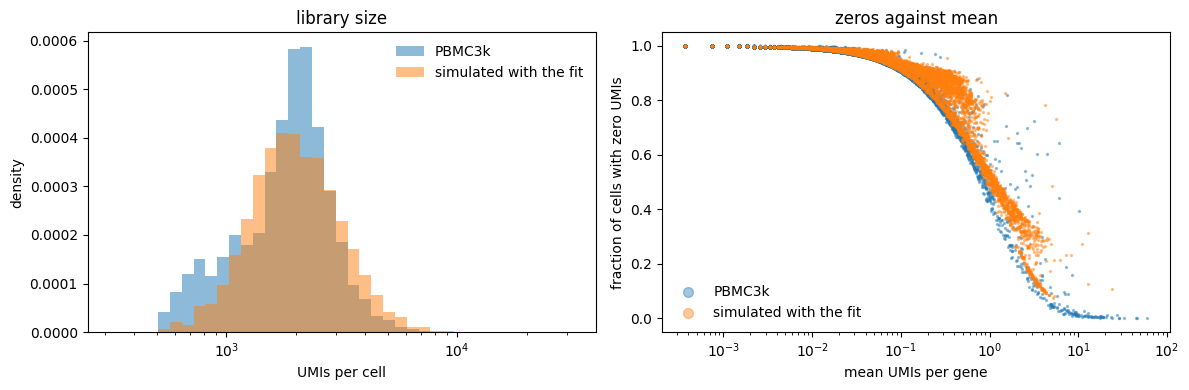

In [14]:
fitted_rna = scRNA(n_cells=est.n_cells, seed=1, **est.scrna_kwargs()).run(cells)
print(f"mean depth drawn for this batch: {fitted_rna.batch.mu_lib_b:,.0f} UMIs (fitted mu_lib {est.hypers.mu_lib:,.0f})")
real_X = pbmc.X.toarray()
sim_X = fitted_rna.observed_counts.values

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for X, label in [(real_X, "PBMC3k"), (sim_X, "simulated with the fit")]:
    lib = X.sum(1)
    print(f"{label}: median {np.median(lib):,.0f} UMIs per cell, CV {lib.std() / lib.mean():.2f}")
    axes[0].hist(lib, bins=np.logspace(2.5, 4.5, 40), alpha=0.5, density=True, label=label)
    axes[1].scatter(X.mean(0), (X == 0).mean(0), s=2, alpha=0.4, label=label)
axes[0].set(xscale="log", xlabel="UMIs per cell", ylabel="density", title="library size")
axes[1].set(xscale="log", xlabel="mean UMIs per gene", ylabel="fraction of cells with zero UMIs",
            title="zeros against mean")
for ax in axes:
    ax.legend(frameon=False, markerscale=5)
plt.tight_layout()
print("dropout midpoint fitted on request:", round(estimate_rna(pbmc, fit_dropout=True).hypers.dropout_mid, 3))

Within eight groups of cells the fitted dispersion is 0.345, against 0.608 over all cells pooled.
The simulated library sizes have about the CV of PBMC3k (0.48 against 0.46) and a higher median (2,406 against 2,197 UMIs).
The per-batch depth offset (`depth_batch_sigma`) drew a mean depth of 2,570 UMIs for this batch, above the fitted 2,367.
Most simulated genes have the zero fraction of PBMC3k at their mean, and a second group of genes has more zeros above about 0.3 UMIs per cell.
These may be genes expressed in only some of the cell types of the tumor.
Asked to fit dropout, `estimate_rna` finds no zeros beyond those of the negative binomial and returns a midpoint of 0.

## Visium

[`Visium`](https://pedrofale.github.io/iscc/reference/Visium/) lays the fixed 10x Visium v1 slide of 4,992 spots over the section and pools the cells within the radius of each spot.
It draws the UMIs of each spot with a log-normal depth (`mu_counts`, `sigma_counts`) scaled by a smooth capture field over the slide (`field_sigma`, `field_lengthscale`).
With `section_frac=1.0` the section is placed as it was cut, centered on the slide.

4,992 spots, 3,900 over tissue, median 7 cells per tissue spot


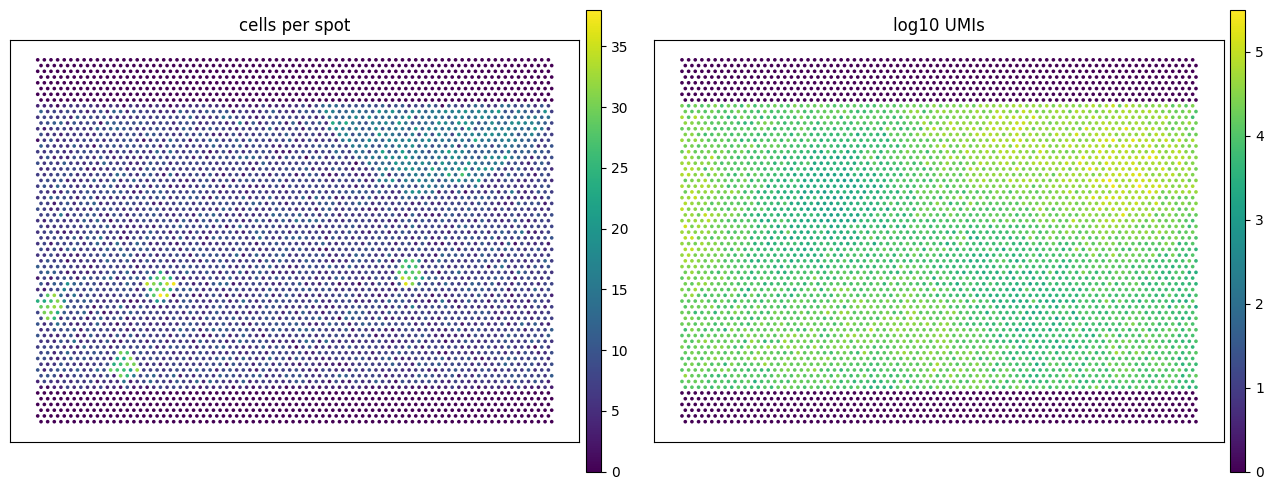

In [15]:
def visium_summary(adata):
    tissue = adata.obs["in_tissue"].values == 1
    umis = np.asarray(adata.X.sum(1)).ravel()
    return {"spots in tissue": tissue.sum(), "mean UMIs per tissue spot": umis[tissue].mean(),
            "median UMIs per tissue spot": np.median(umis[tissue]),
            "mean log10 UMIs per tissue spot": np.log10(umis[tissue]).mean(),
            "Moran's I of the depth": morans_i(umis[tissue], adata.obsm["spatial"][tissue]),
            "share of UMIs outside the tissue": umis[~tissue].sum() / umis.sum()}

visium = Visium(section_frac=1.0, seed=1).run(section)
spots = visium.to_anndata()
tissue = spots.obs["in_tissue"] == 1
print(f"{spots.n_obs:,} spots, {tissue.sum():,} over tissue, "
      f"median {spots.obs['n_cells'][tissue].median():.0f} cells per tissue spot")
spots.obs["log10 UMIs"] = np.log10(1 + spots.obs["total_counts"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sq.pl.spatial_scatter(spots, color="n_cells", img=False, ax=axes[0], title="cells per spot")
sq.pl.spatial_scatter(spots, color="log10 UMIs", img=False, ax=axes[1], title="log10 UMIs")
for ax in axes:
    ax.set(xlabel="", ylabel="")
plt.tight_layout()

The section covers 3,900 of the 4,992 spots, with a median of 7 cells per tissue spot and several times more over the dense glands.
The section is wider than the slide, so the spots without tissue form two bands above and below it.
The depth varies smoothly across the section with the capture field, independently of the tissue.

We switch off the capture field, quarter the depth, and switch on spot swapping, the bleeding of counts from their spot to other spots of the slide as SpotClean models it (Ni et al., 2022), which [`bleed`](https://pedrofale.github.io/iscc/reference/visium_bleed/) implements.
Spot swapping takes a bleeding rate (`bleed_rate`) and the share of the bled counts spread over the whole slide (`bleed_distal`).
The rest spreads through a kernel of sd `bleed_sigma`, and we set all three close to the values fitted to a real section below.
For each run we report the depth of the tissue spots, its spatial autocorrelation (Moran's I, `morans_i`) and the share of the UMIs counted outside the tissue.

In [16]:
settings = {"default": {},
            "flat capture field": dict(field_sigma=0.0),
            "a quarter of the depth": dict(mu_counts=5000),
            "spot swapping": dict(bleed_rate=0.3, bleed_distal=0.3, bleed_sigma=6.5)}
slides = {name: Visium(section_frac=1.0, seed=1, **kw).run(section).to_anndata() for name, kw in settings.items()}
pd.DataFrame({name: visium_summary(a) for name, a in slides.items()}).T.round(3)

,spots in tissue,mean UMIs per tissue spot,median UMIs per tissue spot,mean log10 UMIs per tissue spot,Moran's I of the depth,share of UMIs outside the tissue
default,3900.0,19928.873,12625.5,4.117,0.639,0.000
flat capture field,3900.0,19957.760,17924.5,4.255,0.017,0.000
a quarter of the depth,3900.0,4981.855,3149.5,3.515,0.639,0.000
spot swapping,3900.0,19280.451,13038.0,4.156,0.737,0.033


Without the capture field the depth has no spatial autocorrelation (Moran's I of 0.02 against 0.64).
The mean depth of a tissue spot is close to the `mu_counts` of 20,000 in both runs (19,929 and 19,958 UMIs).
Its median is lower because the depth is log-normal, and more so with the field on (12,626 against 17,925 UMIs).
A quarter of `mu_counts` gives a quarter of the depth.
With spot swapping, 3.3% of the UMIs are counted outside the tissue, where the other runs count none.
The swap also smooths the depth between neighboring spots, which raises its spatial autocorrelation (Moran's I of 0.74 against 0.64).

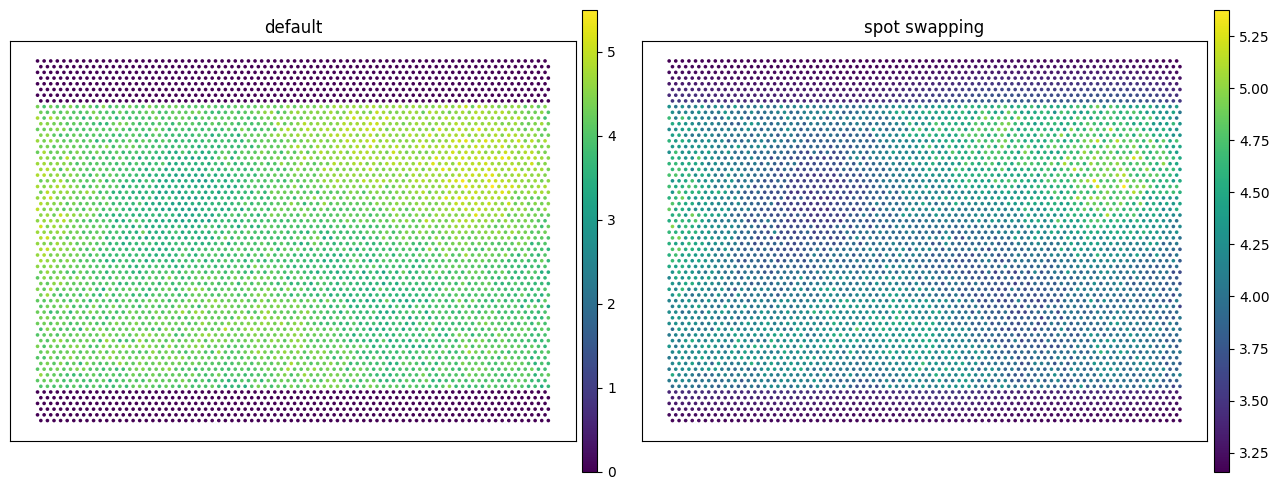

In [17]:
for adata in slides.values():
    adata.obs["log10 UMIs"] = np.log10(1 + adata.obs["total_counts"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["default", "spot swapping"]):
    sq.pl.spatial_scatter(slides[name], color="log10 UMIs", img=False, ax=ax, title=name)
    ax.set(xlabel="", ylabel="")
plt.tight_layout()

With spot swapping, counts spread into the spots without tissue above and below the section, and the distal share adds a floor of counts over the whole slide.

### Fitting the assay to a real section

[`estimate_visium`](https://pedrofale.github.io/iscc/reference/estimate_visium/) fits the depth, the capture field and the count overdispersion of a real section from its tissue spots.
Given every spot of the slide with the `in_tissue` flag of Space Ranger, it also fits the spot swapping from the spots outside the tissue.
We fit it to the breast cancer section V1_Breast_Cancer_Block_A_Section_1 of 10x Genomics.
`scanpy.datasets.visium_sge` downloads its images and spot positions, and we download the raw matrix with every spot from the 10x Genomics website.
The coordinates of a real slide are in pixels, so we rescale them to the unit of `iscc`, in which neighboring spots are 2 apart, before fitting the length scale of the field.

In [18]:
sample = "V1_Breast_Cancer_Block_A_Section_1"
sc.datasets.visium_sge(sample)
folder = sc.settings.datasetdir / sample
raw_h5 = folder / "raw_feature_bc_matrix.h5"
if not raw_h5.exists():
    url = f"https://cf.10xgenomics.com/samples/spatial-exp/1.1.0/{sample}/{sample}_raw_feature_bc_matrix.h5"
    request = urllib.request.Request(url, headers={"User-Agent": "scanpy-user"})
    with urllib.request.urlopen(request) as response, open(raw_h5, "wb") as f:
        shutil.copyfileobj(response, f)
real = sc.read_visium(folder, count_file="raw_feature_bc_matrix.h5")
real.var_names_make_unique()
sc.pp.filter_genes(real, min_counts=1)

xy = real.obsm["spatial"].astype(float)
pitch = np.median(cKDTree(xy).query(xy, k=2)[0][:, 1])
est_visium = estimate_visium(real, coords=xy / pitch * 2.0)
print(f"{real.n_obs:,} spots, {int(real.obs['in_tissue'].sum()):,} in tissue, {real.n_vars:,} detected genes")
print("fitted:", est_visium.fitted)
print(f"mean depth of a tissue spot: {est_visium.diagnostics['bleed']['mu_counts_observed']:,.0f} UMIs observed, "
      f"{est_visium.hypers.mu_counts:,.0f} before spot swapping")
pd.Series(est_visium.visium_kwargs())

4,992 spots, 3,798 in tissue, 25,062 detected genes
fitted: ['mu_counts', 'sigma_counts', 'field_sigma', 'field_lengthscale', 'kappa', 'bleed_rate', 'bleed_distal', 'bleed_sigma', 'edge_sigma']
mean depth of a tissue spot: 21,815 UMIs observed, 22,767 before spot swapping


spot_pitch                    2.0
spot_radius                  0.55
mu_counts            22766.703912
sigma_counts              0.45523
field_lengthscale        18.04158
field_sigma              0.697465
edge_sigma               0.286949
edge_reference             tissue
diffusion_sigma               0.0
bleed_rate               0.309789
bleed_distal             0.302934
bleed_sigma                   6.5
sigma_batch                   0.1
ambient_frac                  0.0
kappa                89211.094789
nb_dispersion                 0.3
dtype: object

The fitted bleeding rate is 0.31, of which 30% goes to the whole slide, and the fitted kernel sd is 6.5, or 3.25 spot pitches.
With the bleed fitted, `estimate_visium` sets the ambient RNA within spots to 0 (`ambient_frac`) and measures the loss of depth at the edge from the tissue (`edge_reference="tissue"`).
Its `mu_counts` is the depth of a tissue spot before swapping, 22,767 UMIs against the observed mean of 21,815.
The count overdispersion `kappa` (89,211) is fitted over the 25,062 genes detected in the real section, where the heterogeneity of the tissue adds to the count noise, so it bounds the technical value from below.
We keep it as fitted.

In [19]:
fitted_visium = Visium(section_frac=1.0, seed=1, **est_visium.visium_kwargs()).run(section)
fitted_spots = fitted_visium.to_anndata()
on_tissue = fitted_spots.obs["in_tissue"] == 1
print(f"mean capture field over the tissue spots: {fitted_spots.obs['capture_field'][on_tissue].mean():.2f}")
pd.DataFrame({"real section": visium_summary(real),
              "simulated with the fit": visium_summary(fitted_spots)}).T.round(3)

mean capture field over the tissue spots: 1.00


,spots in tissue,mean UMIs per tissue spot,median UMIs per tissue spot,mean log10 UMIs per tissue spot,Moran's I of the depth,share of UMIs outside the tissue
real section,3798.0,21814.715,20761.5,4.221,0.742,0.065
simulated with the fit,3900.0,21946.326,14838.0,4.208,0.733,0.033


The simulated tissue spots have the mean depth of the real ones (21,946 against 21,815 UMIs), their mean log depth (log10 4.21 against 4.22) and their spatial autocorrelation (Moran's I 0.73 against 0.74).
Their median depth is lower (14,838 against 20,762 UMIs), because the depth of the real tissue spots is skewed toward deep spots with a tail of shallow ones, while the simulated depth is log-normal (right panel below).
The share of the UMIs counted outside the tissue is lower in the simulation (0.033 against 0.065).
The simulated section runs past the left and right edges of the slide, while the real section has spots without tissue on every side.

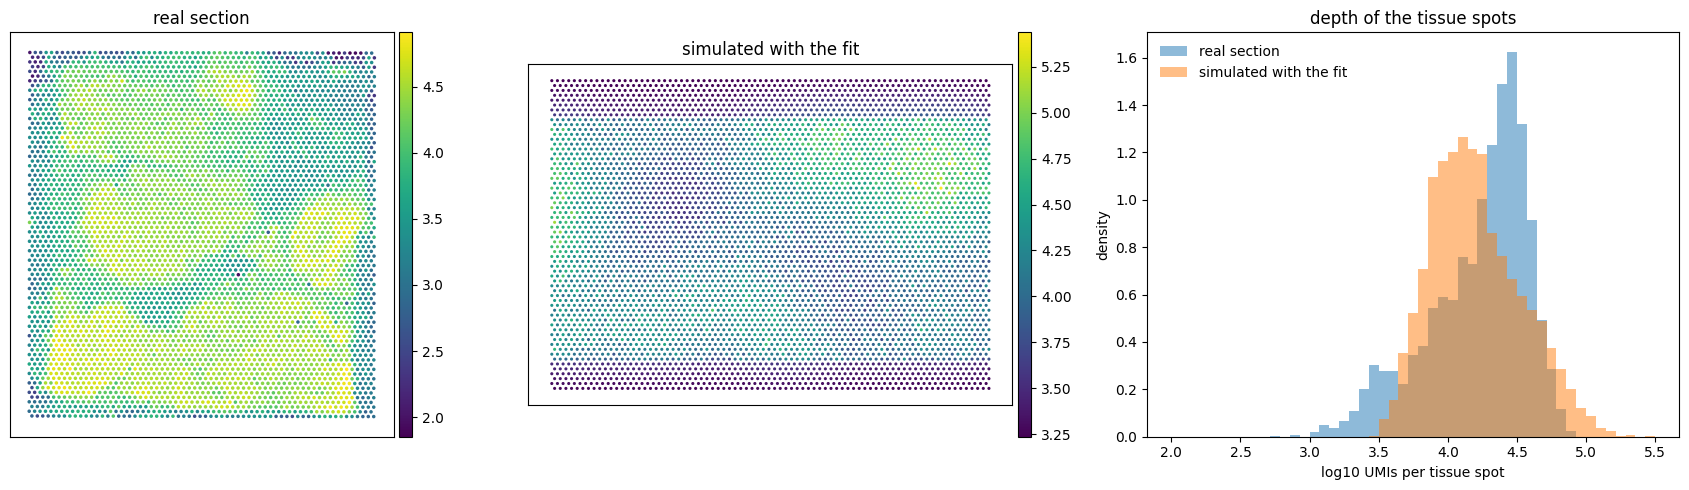

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, adata, title in [(axes[0], real, "real section"), (axes[1], fitted_spots, "simulated with the fit")]:
    adata.obs["log10 UMIs"] = np.log10(1 + np.asarray(adata.X.sum(1)).ravel())
    sq.pl.spatial_scatter(adata, color="log10 UMIs", img=False, ax=ax, title=title)
    ax.set(xlabel="", ylabel="")
    on = adata.obs["in_tissue"] == 1
    axes[2].hist(adata.obs["log10 UMIs"][on], bins=np.linspace(2, 5.5, 50), alpha=0.5, density=True, label=title)
axes[2].set(xlabel="log10 UMIs per tissue spot", ylabel="density", title="depth of the tissue spots")
axes[2].legend(frameon=False)
plt.tight_layout()

The depth of the real section varies in patches that may follow its histology, while the simulated depth follows the capture field, which is independent of the tissue.

## Batches

`run_scrna_batches` measures cells in several batches of one protocol.
Each batch draws its own per-gene factor, the generic batch effect of Splatter with a log-normal sd `sigma_batch`, and its own depth offset (`depth_batch_sigma`), and `batch_kwargs` gives each batch its own parameters.
We split 2,400 cells over three batches, give the second a lower depth and the third more ambient RNA, and merge them with `concat_batches`.
We compare `sigma_batch` 0 and 0.3 by the silhouette of the batch and cell-type labels in PCA space after the standard scanpy normalization.

,silhouette of batch,silhouette of cell type,fitted sigma_batch
sigma_batch,,,
0.0,-0.003,0.275,0.044
0.3,0.108,0.219,0.272


fitted depth per batch: {'batch0': 4301, 'batch1': 1616, 'batch2': 4451}


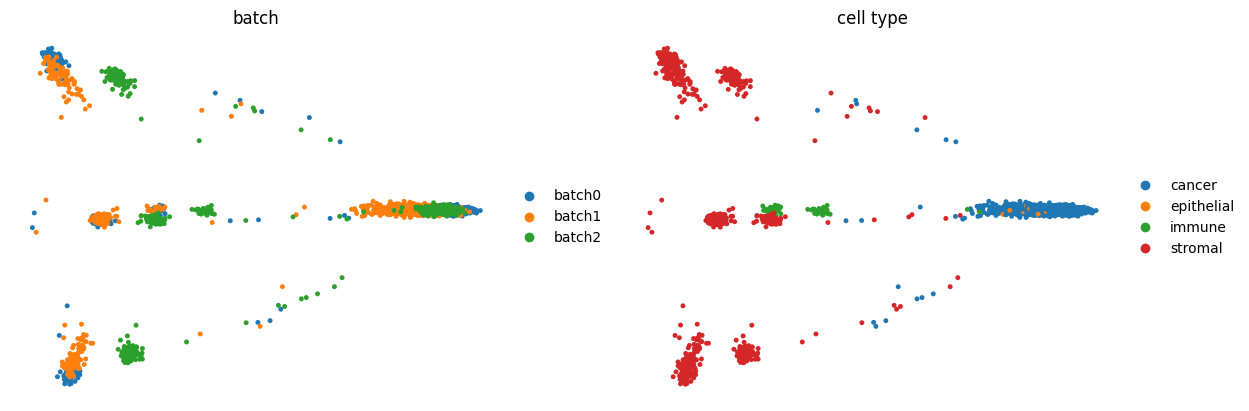

In [21]:
def merged_batches(sigma_batch):
    batches = run_scrna_batches(cells, n_batches=3, design="split", n_cells=800, protocol="10x",
                                sigma_batch=sigma_batch,
                                batch_kwargs=[{}, {"mu_lib": 1500}, {"ambient_frac": 0.2}])
    merged = concat_batches(batches)
    merged.obs["cell type"] = biological_types(merged.obs["clone"])
    batch_fit = estimate_rna(merged, batch_key="batch")
    sc.pp.normalize_total(merged)
    sc.pp.log1p(merged)
    sc.pp.pca(merged, n_comps=20)
    return merged, batch_fit

rows = {}
for sigma_batch in [0.0, 0.3]:
    merged, batch_fit = merged_batches(sigma_batch)
    rows[sigma_batch] = {"silhouette of batch": silhouette_score(merged.obsm["X_pca"], merged.obs["batch"]),
                         "silhouette of cell type": silhouette_score(merged.obsm["X_pca"], merged.obs["cell type"]),
                         "fitted sigma_batch": batch_fit.hypers.sigma_batch}
display(pd.DataFrame(rows).T.rename_axis("sigma_batch").round(3))
print("fitted depth per batch:", {b: round(v["mu_lib"]) for b, v in batch_fit.per_batch.items()})
sc.pl.pca(merged, color=["batch", "cell type"], frameon=False)

With `sigma_batch` 0.3 the batches separate within each cell type (silhouette of the batch labels 0.108 against -0.003), and the cell types separate less (0.219 against 0.275).
`estimate_rna(adata, batch_key="batch")` fits the batch parameters back from the merged counts, with a `sigma_batch` of 0.27 for 0.3 and of 0.04 for 0.
The depth it fits for the second batch (`per_batch`) is the lowest, as we set it.
On real data with several batches, we pass the fitted parameters of each real batch to `batch_kwargs`, so that each simulated batch has the parameters of a real one.
`run_dna_batches` builds batches of the DNA assays in the same way, and `estimate_visium` fits `sigma_batch` from several sections (`section_labels`).

## Data for analysis tools

Every assay returns an AnnData with `to_anndata()` and writes its tables and an h5ad file with `write(path)`, and [`iscc.integrations.to_anndata`](https://pedrofale.github.io/iscc/reference/to_anndata/) packs the true per-cell tables of a sample.
We write the runs of this tutorial to a temporary folder.

In [22]:
out = tempfile.mkdtemp()
bulk["WGS 30x"].write(os.path.join(out, "bulk_wgs"))
sc_dna["DLP+"].write(os.path.join(out, "scdna_dlp"))
fitted_rna.write(os.path.join(out, "scrna_10x"))
fitted_visium.write(os.path.join(out, "visium"))
to_anndata(cells).write_h5ad(os.path.join(out, "truth_dissociated.h5ad"))
for root, _, files in sorted(os.walk(out)):
    for f in sorted(files):
        print(os.path.relpath(os.path.join(root, f), out))

truth_dissociated.h5ad
bulk_wgs/counts.csv
bulk_wgs/dnabatch1.h5ad
scdna_dlp/alt_counts.csv
scdna_dlp/coverage.csv
scdna_dlp/dnabatch2.h5ad
scrna_10x/batch1.h5ad
scrna_10x/umis.csv
visium/spot_cell_counts.csv
visium/spot_cell_ids.csv
visium/spot_crd.csv
visium/spot_umi.csv
visium/visium1.h5ad


The tool tutorials start from these outputs.

- [HMMcopy](tool_hmmcopy.ipynb) calls copy number from the scDNA coverage.
- [ASCAT and PyClone-VI](tool_ascat_pyclonevi.ipynb) estimate purity and copy number from bulk WGS and infer clones from the read counts.
- [clonealign](tool_clonealign.ipynb) assigns scRNA cells to the clones of the scDNA copy number.
- [inferCNV](tool_scrna_cnv.ipynb) infers copy number and malignancy from the scRNA counts.
- [RCTD](tool_rctd.ipynb) deconvolves the Visium spots into cell types.
- [Harmony and scVI](tool_integration.ipynb) integrate the scRNA batches of a [cohort](04_cohort.ipynb).

The pregrown tumors are on the arm-level human genome, so the assays can also count real human genes through the [human genome layer](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/).
[`write_scrna`](https://pedrofale.github.io/iscc/reference/write_scrna/) and [`write_visium`](https://pedrofale.github.io/iscc/reference/write_visium/) then write Cell Ranger and Space Ranger output with the truth, for tools that need gene names and chromosome positions.